In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

# Set random seed for reproducibility
np.random.seed(42)

In [2]:
# Load the dataset
df = pd.read_csv('Social_Media_Addiction_With_Features_engg.csv')

print(f"Dataset shape: {df.shape}")
print(f"\nFirst few rows:")
df.head()

Dataset shape: (609, 35)

First few rows:


,Gender,Occupation,Usage_Intensity,Age,Gender_Encoded,Gender_Male,Facebook_Monthly_Total,Messenger_Monthly_Total,WhatsApp_Monthly_Total,Instagram_Monthly_Total,...,WhatsApp_Weekly_Std,Instagram_Weekly_Std,YouTube_Weekly_Std,TikTok_Weekly_Std,Facebook_Weekly_Consistency,Messenger_Weekly_Consistency,WhatsApp_Weekly_Consistency,Instagram_Weekly_Consistency,YouTube_Weekly_Consistency,TikTok_Weekly_Consistency
0,Male,Employed,Very High,35,1,True,1849.0,1186.0,1989.0,1748.0,...,60.648578,62.519330,69.830151,0.0,0.011315,0.050355,0.016221,0.015743,0.014118,1.0
1,Female,Student,Medium,19,0,False,236.0,210.0,275.0,92.0,...,9.394147,1.825742,2.217356,0.0,0.086100,0.343070,0.096208,0.353889,0.310814,1.0
2,Male,Student,Low,23,1,True,82.0,52.0,83.0,0.0,...,24.171264,0.000000,34.491545,0.0,0.051903,0.053205,0.039728,1.000000,0.028176,1.0
3,Male,Student,Very High,21,1,True,5668.0,1050.0,248.0,351.0,...,22.494444,21.868928,39.251327,0.0,0.009155,0.027092,0.042563,0.043727,0.024844,1.0
4,Female,Student,Very High,19,0,False,1275.0,896.0,543.0,1046.0,...,9.178780,39.034173,32.893768,0.0,0.025697,0.027781,0.098244,0.024979,0.029504,1.0


In [3]:
# Check dataset information
print("Dataset Info:")
print(df.info())
print(f"\nMissing values:\n{df.isnull().sum().sum()}")

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 609 entries, 0 to 608
Data columns (total 35 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Gender                        609 non-null    object 
 1   Occupation                    609 non-null    object 
 2   Usage_Intensity               609 non-null    object 
 3   Age                           609 non-null    int64  
 4   Gender_Encoded                609 non-null    int64  
 5   Gender_Male                   609 non-null    bool   
 6   Facebook_Monthly_Total        609 non-null    float64
 7   Messenger_Monthly_Total       609 non-null    float64
 8   WhatsApp_Monthly_Total        609 non-null    float64
 9   Instagram_Monthly_Total       609 non-null    float64
 10  YouTube_Monthly_Total         609 non-null    float64
 11  TikTok_Monthly_Total          609 non-null    float64
 12  Total_Monthly_Usage           609 non-null    floa

In [4]:
features = [
    'Age',
    'Total_Monthly_Usage','Avg_Platform_Usage','Active_Platforms_Count',
    'Platform_Diversity_Score','Dominant_Platform_Percentage','Usage_Concentration',
    'Social_Networking_Usage','Messaging_Usage','Video_Platform_Usage','Social_to_Messaging_Ratio',
    'Overall_Consistency',
    'YouTube_Monthly_Total','WhatsApp_Monthly_Total','Instagram_Monthly_Total','Facebook_Monthly_Total',
    'Messenger_Monthly_Total','TikTok_Monthly_Total'
]

In [5]:
# Prepare features for clustering
X = df[features].copy()

print(f"Features shape: {X.shape}")
print(f"\nFeatures summary:")
X.describe()

Features shape: (609, 18)

Features summary:


,Age,Total_Monthly_Usage,Avg_Platform_Usage,Active_Platforms_Count,Platform_Diversity_Score,Dominant_Platform_Percentage,Usage_Concentration,Social_Networking_Usage,Messaging_Usage,Video_Platform_Usage,Social_to_Messaging_Ratio,Overall_Consistency,YouTube_Monthly_Total,WhatsApp_Monthly_Total,Instagram_Monthly_Total,Facebook_Monthly_Total,Messenger_Monthly_Total,TikTok_Monthly_Total
count,609.000000,609.000000,609.000000,609.000000,609.000000,609.000000,609.000000,609.000000,609.000000,609.000000,609.000000,609.000000,609.000000,609.000000,609.000000,609.000000,609.000000,609.000000
mean,25.210181,6161.513957,1026.918993,5.101806,0.850301,41.251178,0.412266,3048.543514,1878.178982,1234.791461,2.264025,0.214152,1234.791461,886.175698,701.078818,1656.367816,992.003284,691.096880
std,6.677621,3421.786395,570.297732,0.794397,0.132399,12.525332,0.125121,2199.740088,1444.288950,1302.031758,2.360543,0.126737,1302.031758,929.056475,802.070965,2014.757643,979.667645,1141.003971
min,16.000000,10.000000,1.666667,2.000000,0.333333,21.585032,0.215817,0.000000,4.000000,0.000000,0.000000,0.015705,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,21.000000,3649.000000,608.166667,5.000000,0.833333,32.143245,0.321398,1317.000000,884.000000,363.000000,0.933159,0.146074,363.000000,316.000000,71.000000,421.000000,366.000000,0.000000
50%,23.000000,5831.000000,971.833333,5.000000,0.833333,38.133069,0.381111,2568.000000,1572.000000,885.000000,1.548798,0.188500,885.000000,663.000000,472.000000,936.000000,723.000000,0.000000
75%,26.000000,8298.000000,1383.000000,6.000000,1.000000,45.848871,0.458399,4418.000000,2409.000000,1606.000000,2.661575,0.322207,1606.000000,1193.000000,1063.000000,1773.000000,1271.000000,1098.000000
max,50.000000,16760.000000,2793.333333,6.000000,1.000000,89.124454,0.891172,12292.000000,11443.000000,8648.000000,19.361757,0.938996,8648.000000,10422.000000,7349.000000,11956.000000,7344.000000,4314.000000


In [6]:
# Standardize the features (important for K-Means)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Scaled features shape: {X_scaled.shape}")
print(f"Mean of scaled features (should be ~0): {X_scaled.mean():.6f}")
print(f"Std of scaled features (should be ~1): {X_scaled.std():.6f}")

Scaled features shape: (609, 18)
Mean of scaled features (should be ~0): 0.000000
Std of scaled features (should be ~1): 1.000000


In [7]:
# Elbow Method - Find optimal number of clusters
inertias = []
silhouette_scores = []
k_range = range(2, 8)

print("Computing elbow method metrics...")
for k_val in k_range:
    kmeans_temp = KMeans(n_clusters=k_val, random_state=42, n_init=10, max_iter=300)
    kmeans_temp.fit(X_scaled)
    inertias.append(kmeans_temp.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, kmeans_temp.labels_))
    print(f"k={k_val}: Inertia={kmeans_temp.inertia_:.2f}, Silhouette={silhouette_scores[-1]:.4f}")

print("\nElbow method computation completed!")

Computing elbow method metrics...


c:\Users\ThinkPad T14\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
c:\Users\ThinkPad T14\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
c:\Users\ThinkPad T14\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
c:\Users\ThinkPad T14\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to 

k=2: Inertia=8581.26, Silhouette=0.3168
k=3: Inertia=7269.01, Silhouette=0.2134
k=4: Inertia=6409.14, Silhouette=0.2273
k=5: Inertia=5698.73, Silhouette=0.2363
k=6: Inertia=5106.32, Silhouette=0.2415
k=7: Inertia=4616.07, Silhouette=0.2465

Elbow method computation completed!


c:\Users\ThinkPad T14\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(


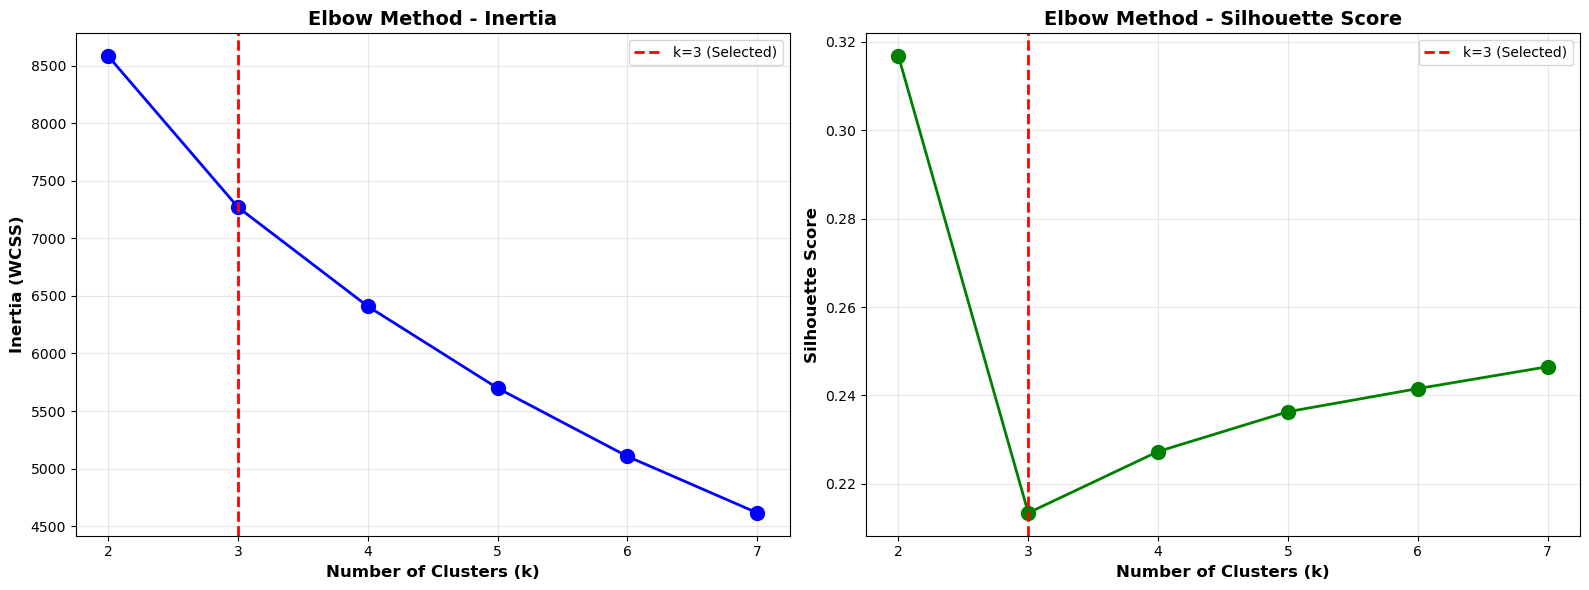


Optimal k=3 selected based on elbow method analysis


In [8]:
# Visualize Elbow Graph
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Inertia (Within-cluster sum of squares)
axes[0].plot(k_range, inertias, 'bo-', linewidth=2, markersize=10)
axes[0].set_xlabel('Number of Clusters (k)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Inertia (WCSS)', fontsize=12, fontweight='bold')
axes[0].set_title('Elbow Method - Inertia', fontsize=14, fontweight='bold')
axes[0].grid(True, alpha=0.3)
axes[0].axvline(x=3, color='r', linestyle='--', linewidth=2, label='k=3 (Selected)')
axes[0].legend()
axes[0].set_xticks(k_range)

# Plot 2: Silhouette Score
axes[1].plot(k_range, silhouette_scores, 'go-', linewidth=2, markersize=10)
axes[1].set_xlabel('Number of Clusters (k)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Silhouette Score', fontsize=12, fontweight='bold')
axes[1].set_title('Elbow Method - Silhouette Score', fontsize=14, fontweight='bold')
axes[1].grid(True, alpha=0.3)
axes[1].axvline(x=3, color='r', linestyle='--', linewidth=2, label='k=3 (Selected)')
axes[1].legend()
axes[1].set_xticks(k_range)

plt.tight_layout()
plt.show()

print(f"\nOptimal k=3 selected based on elbow method analysis")

In [9]:
# Apply K-Means clustering with k=3
k = 3
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10, max_iter=300)
cluster_labels = kmeans.fit_predict(X_scaled)

# Add cluster labels to the original dataframe
df['Cluster'] = cluster_labels

print(f"K-Means clustering completed with k={k}")
print(f"\nCluster distribution:")
print(df['Cluster'].value_counts().sort_index())
print(f"\nCluster percentages:")
print((df['Cluster'].value_counts(normalize=True).sort_index() * 100).round(2))

K-Means clustering completed with k=3

Cluster distribution:
Cluster
0    293
1    200
2    116
Name: count, dtype: int64

Cluster percentages:
Cluster
0    48.11
1    32.84
2    19.05
Name: proportion, dtype: float64


c:\Users\ThinkPad T14\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(


In [10]:
# Evaluate clustering quality
silhouette_avg = silhouette_score(X_scaled, cluster_labels)
davies_bouldin = davies_bouldin_score(X_scaled, cluster_labels)
calinski_score = calinski_harabasz_score(X_scaled, cluster_labels)

print("Clustering Quality Metrics:")
print(f"Silhouette Score: {silhouette_avg:.4f} (Range: -1 to 1, higher is better)")
print(f"Davies-Bouldin Index: {davies_bouldin:.4f} (Lower is better)")
print(f"Calinski-Harabasz Score: {calinski_score:.4f} (Higher is better)")
print(f"\nInertia (Within-cluster sum of squares): {kmeans.inertia_:.2f}")

Clustering Quality Metrics:
Silhouette Score: 0.2134 (Range: -1 to 1, higher is better)
Davies-Bouldin Index: 1.5703 (Lower is better)
Calinski-Harabasz Score: 153.9379 (Higher is better)

Inertia (Within-cluster sum of squares): 7269.01


In [ ]:
# Analyze cluster characteristicsustering Quality Metrics:
Silhouette Score: 0.2134 (Range: -1 to 1, higher is better)
Davies-Bouldin Index: 1.5703 (Lower is better)
Calinski-Harabasz Score: 153.9379 (Higher is better)
print("Cluster Analysis by Key Features:\n")

# Select key features for analysis
key_features = ['Age', 'Total_Monthly_Usage', 'Avg_Platform_Usage', 
                'Active_Platforms_Count', 'Usage_Concentration', 
                'Overall_Consistency']

for cluster_id in range(k):
    print(f"\n{'='*60}")
    print(f"Cluster {cluster_id} (n={sum(cluster_labels == cluster_id)} users)")
    print(f"{'='*60}")
    
    cluster_data = df[df['Cluster'] == cluster_id]
    
    for feature in key_features:
        if feature in df.columns:
            mean_val = cluster_data[feature].mean()
            print(f"  {feature}: {mean_val:.2f}")
    

Cluster Analysis by Key Features:


Cluster 0 (n=293 users)
  Age: 27.97
  Total_Monthly_Usage: 4647.08
  Avg_Platform_Usage: 774.51
  Active_Platforms_Count: 4.72
  Usage_Concentration: 0.37
  Overall_Consistency: 0.27

Cluster 1 (n=200 users)
  Age: 22.38
  Total_Monthly_Usage: 5626.46
  Avg_Platform_Usage: 937.74
  Active_Platforms_Count: 5.98
  Usage_Concentration: 0.38
  Overall_Consistency: 0.10

Cluster 2 (n=116 users)
  Age: 23.14
  Total_Monthly_Usage: 10909.28
  Avg_Platform_Usage: 1818.21
  Active_Platforms_Count: 4.55
  Usage_Concentration: 0.57
  Overall_Consistency: 0.26


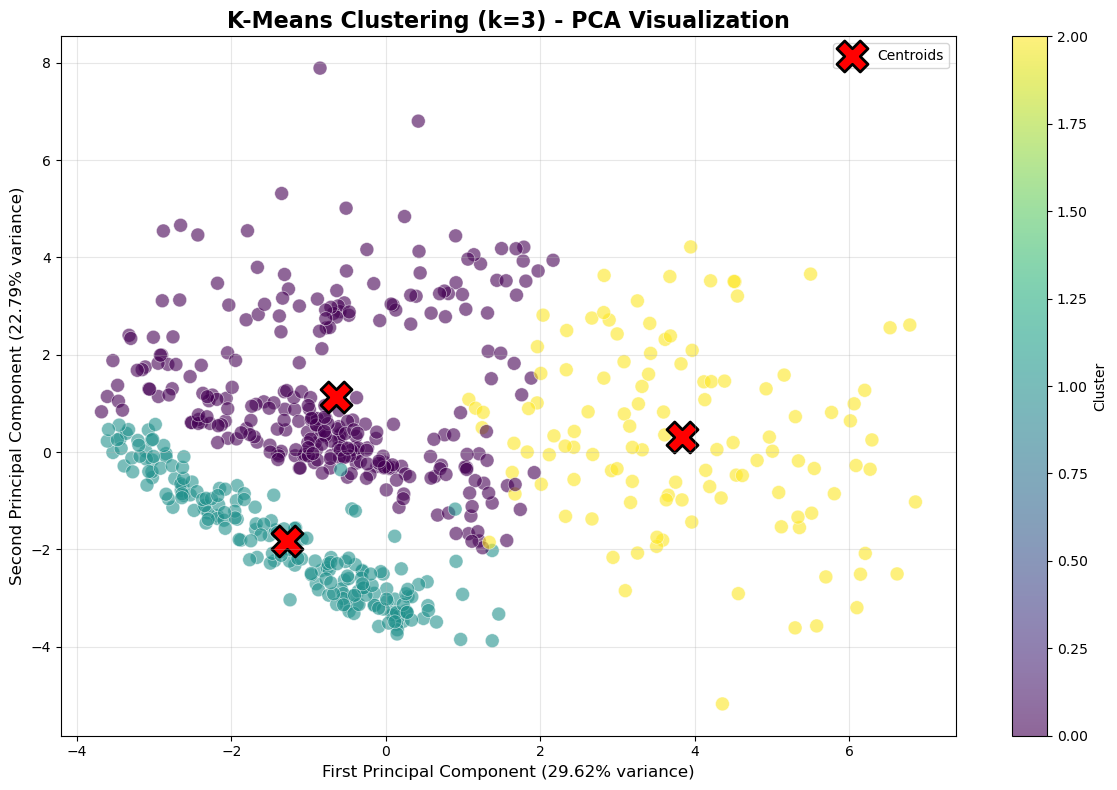

In [12]:
# Visualize clusters using PCA (2D projection)
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(12, 8))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=cluster_labels, cmap='viridis', 
                     alpha=0.6, edgecolors='w', linewidth=0.5, s=100)

# Plot cluster centers
centers_pca = pca.transform(kmeans.cluster_centers_)
plt.scatter(centers_pca[:, 0], centers_pca[:, 1], c='red', marker='X', 
           s=500, edgecolors='black', linewidth=2, label='Centroids')

plt.title(f'K-Means Clustering (k={k}) - PCA Visualization', fontsize=16, fontweight='bold')
plt.xlabel(f'First Principal Component ({pca.explained_variance_ratio_[0]:.2%} variance)', fontsize=12)
plt.ylabel(f'Second Principal Component ({pca.explained_variance_ratio_[1]:.2%} variance)', fontsize=12)
plt.colorbar(scatter, label='Cluster')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#print(f"\nTotal variance explained by 2 PCs: {sum(pca.explained_variance_ratio_):.2%}")

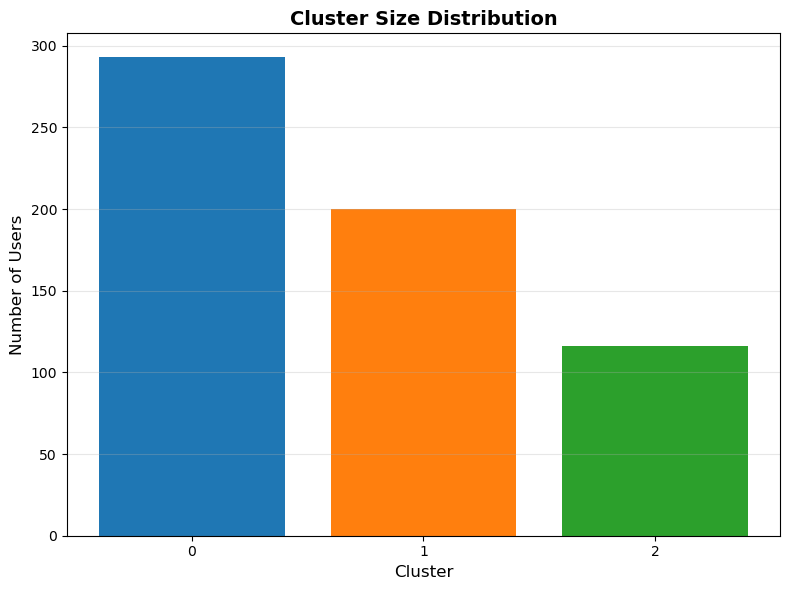

In [13]:
# Visualize cluster distribution
# fig, axes = plt.subplots(2, 2, figsize=(15, 10))

#  Cluster size distribution
plt.figure(figsize=(8,6))
plt.bar(range(k), df['Cluster'].value_counts().sort_index().values, 
              color=['#1f77b4', '#ff7f0e', '#2ca02c'][:k])
plt.xlabel('Cluster', fontsize=12)
plt.ylabel('Number of Users', fontsize=12)
plt.title('Cluster Size Distribution', fontsize=14, fontweight='bold')
plt.xticks(range(k))
plt.grid(True, alpha=0.3, axis='y')



plt.tight_layout()
plt.show()

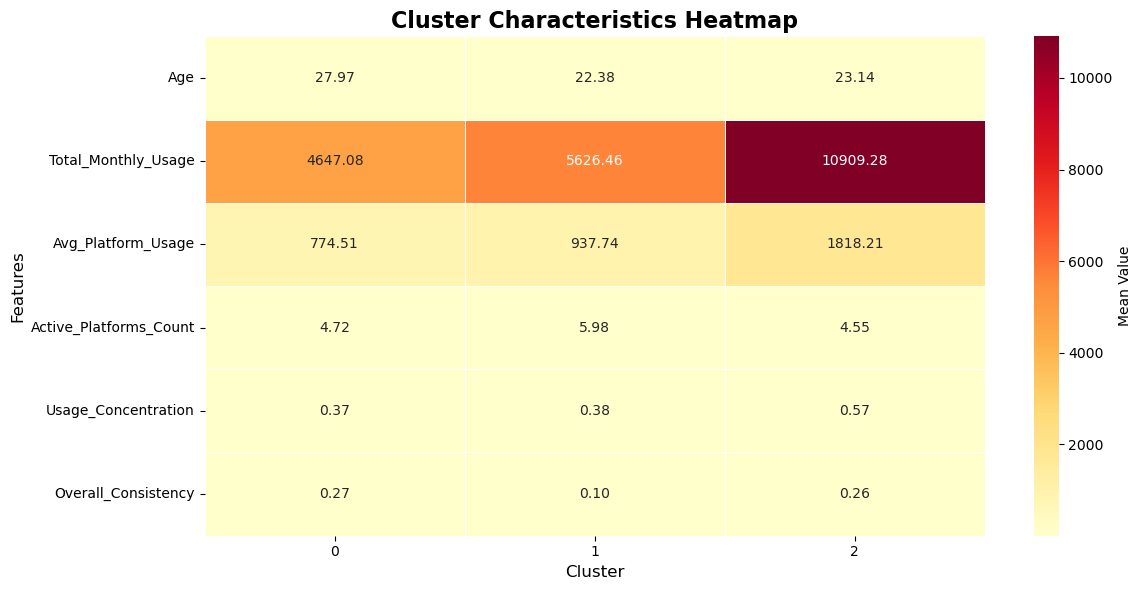

In [14]:
# Heatmap of cluster characteristics
cluster_summary = df.groupby('Cluster')[key_features].mean()

plt.figure(figsize=(12, 6))
sns.heatmap(cluster_summary.T, annot=True, fmt='.2f', cmap='YlOrRd', 
           cbar_kws={'label': 'Mean Value'}, linewidths=0.5)
plt.title('Cluster Characteristics Heatmap', fontsize=16, fontweight='bold')
plt.xlabel('Cluster', fontsize=12)
plt.ylabel('Features', fontsize=12)
plt.tight_layout()
plt.show()

In [15]:
# Assign meaningful labels to clusters based on usage patterns
# Analyze average Total_Monthly_Usage for each cluster to determine intensity
cluster_usage_avg = df.groupby('Cluster')['Total_Monthly_Usage'].mean().sort_values()

print("Average Total Monthly Usage by Cluster:")
print(cluster_usage_avg)
print("\nMapping clusters to risk levels based on usage intensity...")

# Create mapping: lowest usage = Safe (0), medium = At Risk (1), highest = Addicted (2)
cluster_mapping = {
    cluster_usage_avg.index[0]: 0,  # Safe
    cluster_usage_avg.index[1]: 1,  # At Risk
    cluster_usage_avg.index[2]: 2   # Addicted
}

# Label names for reference
label_names = {0: 'Safe', 1: 'At Risk', 2: 'Addicted'}

print(f"\nCluster Mapping:")
for cluster_id, target_value in cluster_mapping.items():
    avg_usage = cluster_usage_avg[cluster_id]
    print(f"  Cluster {cluster_id} -> {target_value} ({label_names[target_value]}) | Avg Usage: {avg_usage:.2f} min/month")

Average Total Monthly Usage by Cluster:
Cluster
0     4647.078498
1     5626.460000
2    10909.275862
Name: Total_Monthly_Usage, dtype: float64

Mapping clusters to risk levels based on usage intensity...

Cluster Mapping:
  Cluster 0 -> 0 (Safe) | Avg Usage: 4647.08 min/month
  Cluster 1 -> 1 (At Risk) | Avg Usage: 5626.46 min/month
  Cluster 2 -> 2 (Addicted) | Avg Usage: 10909.28 min/month


In [16]:
# Create Target column with numeric labels
df['Target'] = df['Cluster'].map(cluster_mapping)

print("Target column created successfully!")
print(f"\nTarget distribution:")
target_dist = df['Target'].value_counts().sort_index()
for target_val in target_dist.index:
    count = target_dist[target_val]
    pct = (count / len(df)) * 100
    print(f"  {target_val} ({label_names[target_val]:10s}): {count:4d} users ({pct:5.2f}%)")

# Display sample rows
print(f"\nSample rows with Target labels:")
df[['Gender', 'Age', 'Occupation', 'Total_Monthly_Usage', 'Usage_Intensity', 'Cluster', 'Target']].head(10)

Target column created successfully!

Target distribution:
  0 (Safe      ):  293 users (48.11%)
  1 (At Risk   ):  200 users (32.84%)
  2 (Addicted  ):  116 users (19.05%)

Sample rows with Target labels:


,Gender,Age,Occupation,Total_Monthly_Usage,Usage_Intensity,Cluster,Target
0,Male,35,Employed,7219.0,Very High,0,0
1,Female,19,Student,876.0,Medium,0,0
2,Male,23,Student,323.0,Low,0,0
3,Male,21,Student,8109.0,Very High,2,2
4,Female,19,Student,4872.0,Very High,0,0
5,Female,23,Student,3599.0,Very High,0,0
6,Female,25,Student,1978.0,High,1,1
7,Male,43,Employed,6162.0,Very High,0,0
8,Male,24,Student,9091.0,Very High,2,2
9,Female,25,Student,1950.0,High,1,1


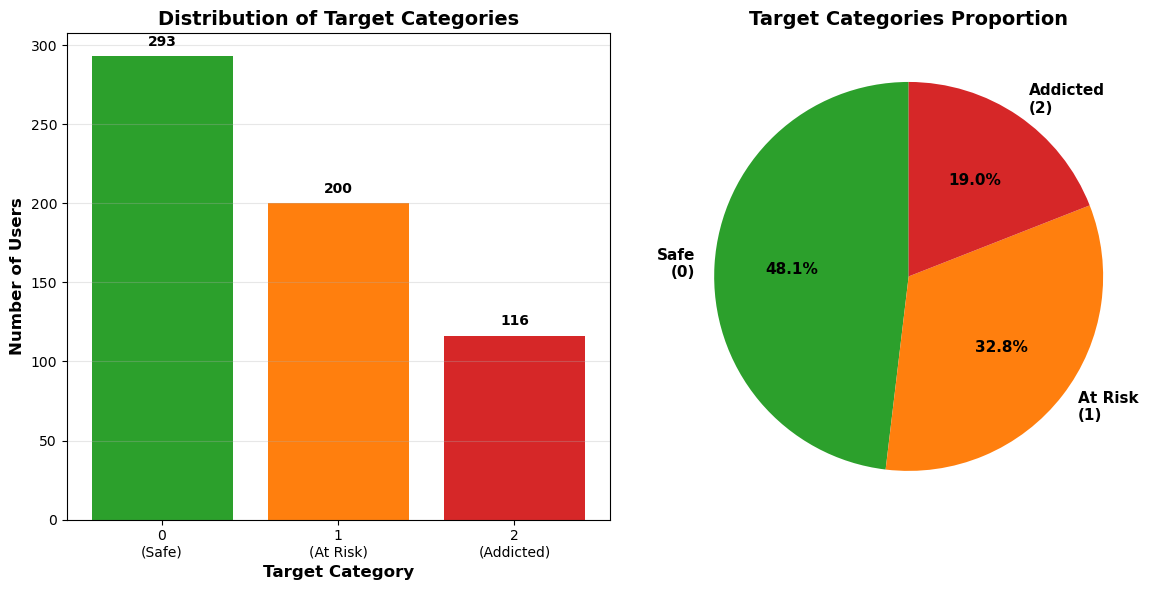

In [17]:
# Visualize Target distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Plot 1: Count plot
target_counts = df['Target'].value_counts().sort_index()
target_labels = [f"{val}\n({label_names[val]})" for val in target_counts.index]
colors = ['#2ca02c', '#ff7f0e', '#d62728']
axes[0].bar(range(len(target_counts)), target_counts.values, color=colors, tick_label=target_labels)
axes[0].set_xlabel('Target Category', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Number of Users', fontsize=12, fontweight='bold')
axes[0].set_title('Distribution of Target Categories', fontsize=14, fontweight='bold')
axes[0].grid(True, alpha=0.3, axis='y')
for i, v in enumerate(target_counts.values):
    axes[0].text(i, v + 5, str(v), ha='center', va='bottom', fontweight='bold')

# Plot 2: Pie chart
pie_labels = [f"{label_names[val]}\n({val})" for val in target_counts.index]
axes[1].pie(target_counts.values, labels=pie_labels, autopct='%1.1f%%',
           colors=colors, startangle=90,
           textprops={'fontsize': 11, 'fontweight': 'bold'})
axes[1].set_title('Target Categories Proportion', fontsize=14, fontweight='bold')

# Plot 3: Box plot of Total Monthly Usage by Target
# bp = axes[2].boxplot([df[df['Target'] == val]['Total_Monthly_Usage'].values 
#                       for val in sorted(df['Target'].unique())],
#                      labels=[f"{val}\n({label_names[val]})" for val in sorted(df['Target'].unique())], 
#                      patch_artist=True)
# for patch, color in zip(bp['boxes'], colors):
#     patch.set_facecolor(color)
# axes[2].set_xlabel('Target Category', fontsize=12, fontweight='bold')
# axes[2].set_ylabel('Total Monthly Usage (minutes)', fontsize=12, fontweight='bold')
# axes[2].set_title('Usage Distribution by Target Category', fontsize=14, fontweight='bold')
# axes[2].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

In [18]:
# Save the dataset with cluster labels and target column
output_path_with_target = r'c:\Users\ThinkPad T14\Downloads\my essential\my project work\Experimental\Social_Media_Addiction_With_Features_And_Target.csv'
df.to_csv(output_path_with_target, index=False)

print(f"✓ Dataset with Cluster and Target labels saved successfully!")
print(f"  File: {output_path_with_target}")
print(f"\nDataset Details:")
print(f"  Total Rows: {len(df)}")
print(f"  Total Columns: {len(df.columns)}")
print(f"  Cluster Column: Original cluster IDs (0, 1, 2)")
print(f"  Target Column: Risk levels (0=Safe, 1=At Risk, 2=Addicted)")
print(f"\nTarget Summary:")
for target_val in sorted(df['Target'].unique()):
    count = len(df[df['Target'] == target_val])
    pct = (count / len(df)) * 100
    avg_usage = df[df['Target'] == target_val]['Total_Monthly_Usage'].mean()
    print(f"  {target_val} ({label_names[target_val]:10s}): {count:4d} users ({pct:5.2f}%) - Avg Usage: {avg_usage:7.2f} min/month")

✓ Dataset with Cluster and Target labels saved successfully!
  File: c:\Users\ThinkPad T14\Downloads\my essential\my project work\Experimental\Social_Media_Addiction_With_Features_And_Target.csv

Dataset Details:
  Total Rows: 609
  Total Columns: 37
  Cluster Column: Original cluster IDs (0, 1, 2)
  Target Column: Risk levels (0=Safe, 1=At Risk, 2=Addicted)

Target Summary:
  0 (Safe      ):  293 users (48.11%) - Avg Usage: 4647.08 min/month
  1 (At Risk   ):  200 users (32.84%) - Avg Usage: 5626.46 min/month
  2 (Addicted  ):  116 users (19.05%) - Avg Usage: 10909.28 min/month


In [19]:
# Check the distribution of Total_Monthly_Usage for each Target class
for target_val in [0, 1, 2]:
    usage_data = df[df['Target'] == target_val]['Total_Monthly_Usage']
    print(f"\nTarget {target_val} ({label_names[target_val]}):")
    print(f"  Min: {usage_data.min():.0f}")
    print(f"  Max: {usage_data.max():.0f}")
    print(f"  25th percentile: {usage_data.quantile(0.25):.0f}")
    print(f"  75th percentile: {usage_data.quantile(0.75):.0f}")


Target 0 (Safe):
  Min: 10
  Max: 9791
  25th percentile: 3254
  75th percentile: 6198

Target 1 (At Risk):
  Min: 827
  Max: 10893
  25th percentile: 3379
  75th percentile: 7842

Target 2 (Addicted):
  Min: 5744
  Max: 16760
  25th percentile: 8864
  75th percentile: 13057


## Save Model and Scaler for Future Predictions

Now we'll save the trained model, scaler, and mappings so they can be loaded to predict new users.

In [20]:
import pickle

# Save the trained K-means model
model_path = r'c:\Users\ThinkPad T14\Downloads\my essential\my project work\Experimental\my_kmeans_model.pkl'
with open(model_path, 'wb') as f:
    pickle.dump(kmeans, f)

# Save the scaler
scaler_path = r'c:\Users\ThinkPad T14\Downloads\my essential\my project work\Experimental\my_scaler.pkl'
with open(scaler_path, 'wb') as f:
    pickle.dump(scaler, f)

# Save cluster mapping and label names
mapping_path = r'c:\Users\ThinkPad T14\Downloads\my essential\my project work\Experimental\my_cluster_mapping.pkl'
mapping_data = {
    'cluster_mapping': cluster_mapping,
    'label_names': label_names,
    'features': features
}
with open(mapping_path, 'wb') as f:
    pickle.dump(mapping_data, f)

print("✓ Model, scaler, and mappings saved successfully!")
print(f"\nSaved files:")
print(f"  1. K-Means Model: {model_path}")
print(f"  2. Scaler: {scaler_path}")
print(f"  3. Mappings: {mapping_path}")
print(f"\nThese files can be loaded to predict new users without retraining!")

✓ Model, scaler, and mappings saved successfully!

Saved files:
  1. K-Means Model: c:\Users\ThinkPad T14\Downloads\my essential\my project work\Experimental\my_kmeans_model.pkl
  2. Scaler: c:\Users\ThinkPad T14\Downloads\my essential\my project work\Experimental\my_scaler.pkl
  3. Mappings: c:\Users\ThinkPad T14\Downloads\my essential\my project work\Experimental\my_cluster_mapping.pkl

These files can be loaded to predict new users without retraining!
